# 02 - Exploratory data analysis (EDA)

**Goal:** understand what drives churn in this data and use that to decide which features to build.

- Input: the cleaned files from notebook 01 (`data/processed/*_clean.csv`).
- **Any insight that guides a modelling decision uses the TRAIN rows only** (Jan-Aug 2025, 665 customers).
  Charts that use all 1,020 customers are clearly labelled "all customers".
- Each chart is saved to `reports/figures/eda_*.png`.

Colours used in every chart: **blue = stayed (not churned)**, **orange = churned**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10, "font.size": 10,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"eda_{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

date_cols = ["snapshot_date", "signup_date", "contract_end_date", "last_login_date",
             "last_bill_due_date", "last_payment_date"]
parts = []
for name in ["train", "validation", "test"]:
    part = pd.read_csv(ROOT / "data" / "processed" / f"{name}_clean.csv", parse_dates=date_cols)
    part["split"] = name
    parts.append(part)
data = pd.concat(parts, ignore_index=True)
TARGET = "churn_next_30d"

# Simple helper columns used only for EDA (notebook 03 builds the real features)
data["tenure_days"] = (data["snapshot_date"] - data["signup_date"]).dt.days
data["tenure_band"] = pd.cut(data["tenure_days"] / 30.4, [0, 6, 12, 24, np.inf], right=False,
                             labels=["0-6m", "7-12m", "13-24m", "25m+"]).astype(str)
data["churn_label"] = data[TARGET].map({0: "Stayed", 1: "Churned"})

train = data[data["split"] == "train"].copy()
print("All customers:", len(data), "| train:", len(train))

All customers: 1020 | train: 665


## 1. Target: how many customers churn?

All customers: 226 churned of 1020 -> churn rate 22.2%
Train only:    151 churned of 665 -> churn rate 22.7%
Accuracy of a model that always says 'will not churn' (train): 77.3%


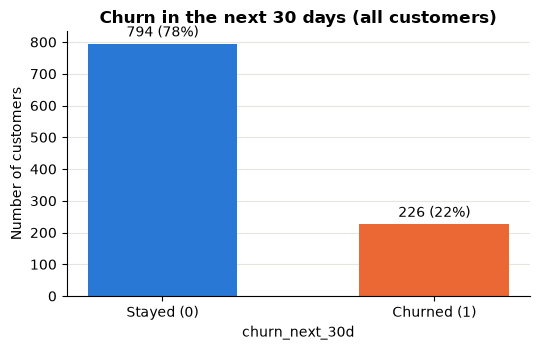

In [2]:
counts = data[TARGET].value_counts().sort_index()
rate_all, rate_train = data[TARGET].mean(), train[TARGET].mean()
print(f"All customers: {counts[1]} churned of {len(data)} -> churn rate {rate_all:.1%}")
print(f"Train only:    {train[TARGET].sum()} churned of {len(train)} -> churn rate {rate_train:.1%}")
print(f"Accuracy of a model that always says 'will not churn' (train): {1 - rate_train:.1%}")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(["Stayed (0)", "Churned (1)"], counts.values, color=[BLUE, ORANGE], width=0.55)
for bar, n in zip(bars, counts.values):
    ax.annotate(f"{n} ({n / len(data):.0%})", (bar.get_x() + bar.get_width() / 2, n),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
ax.set_title("Churn in the next 30 days (all customers)")
ax.set_xlabel("churn_next_30d")
ax.set_ylabel("Number of customers")
save(fig, "target_distribution")

**What this shows:** about 1 in 5 customers churns (22%), so the classes are imbalanced. A useless model that
always predicts "will not churn" would already be about 77% accurate while catching zero churners. That is why
we judge models with **PR-AUC, recall and precision of the churn class**, not accuracy.

## 2. Churn rate over time

,customers,churn_rate,split
snapshot_date,,,
2025-01-31,80,0.250,train
2025-02-28,101,0.208,train
2025-03-31,96,0.208,train
2025-04-30,67,0.254,train
2025-05-31,88,0.193,train
2025-06-30,82,0.171,train
2025-07-31,76,0.263,train
2025-08-31,75,0.293,train
2025-09-30,79,0.291,validation


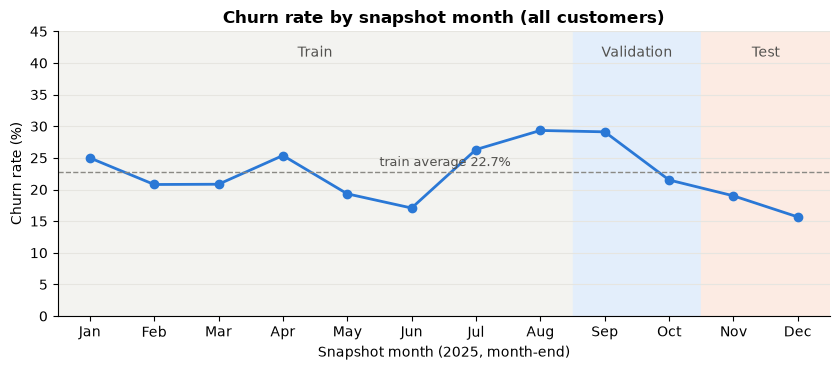

In [3]:
monthly = data.groupby("snapshot_date").agg(customers=(TARGET, "size"), churn_rate=(TARGET, "mean"))
monthly["split"] = data.groupby("snapshot_date")["split"].first()
display(monthly.assign(churn_rate=monthly["churn_rate"].round(3)))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(monthly))                      # one position per snapshot month
ax.plot(x, monthly["churn_rate"] * 100, color=BLUE, linewidth=2, marker="o", markersize=6)
# shade the three time splits
shade = {"train": "#f3f3f0", "validation": "#e3eefb", "test": "#fcebe3"}
for split in ["train", "validation", "test"]:
    pos = x[monthly["split"].to_numpy() == split]
    ax.axvspan(pos.min() - 0.5, pos.max() + 0.5, color=shade[split], zorder=0)
    ax.text(pos.mean(), 41, split.capitalize(), ha="center", color="#52514e")
ax.axhline(rate_train * 100, color=GREY, linestyle="--", linewidth=1)
ax.text(4.5, rate_train * 100 + 1, f"train average {rate_train:.1%}", color="#52514e", fontsize=9)
ax.set_xticks(x, monthly.index.strftime("%b"))
ax.set_xlim(-0.5, len(monthly) - 0.5)
ax.set_ylim(0, 45)
ax.set_title("Churn rate by snapshot month (all customers)")
ax.set_xlabel("Snapshot month (2025, month-end)")
ax.set_ylabel("Churn rate (%)")
save(fig, "churn_rate_over_time")

**What this shows:** the churn rate moves from month to month (roughly 15-30%), and the test months
(Nov-Dec) churn less than validation (Sep-Oct). In real use the model is trained on the past and scores the future, so we
split **by time** rather than randomly. The test score then also reflects this kind of drift.

## 3. Churn rate by customer segment (train)

The dashed line is the train average. Bars above the line are higher-risk segments.
The number under each bar label is how many training customers are in that group.

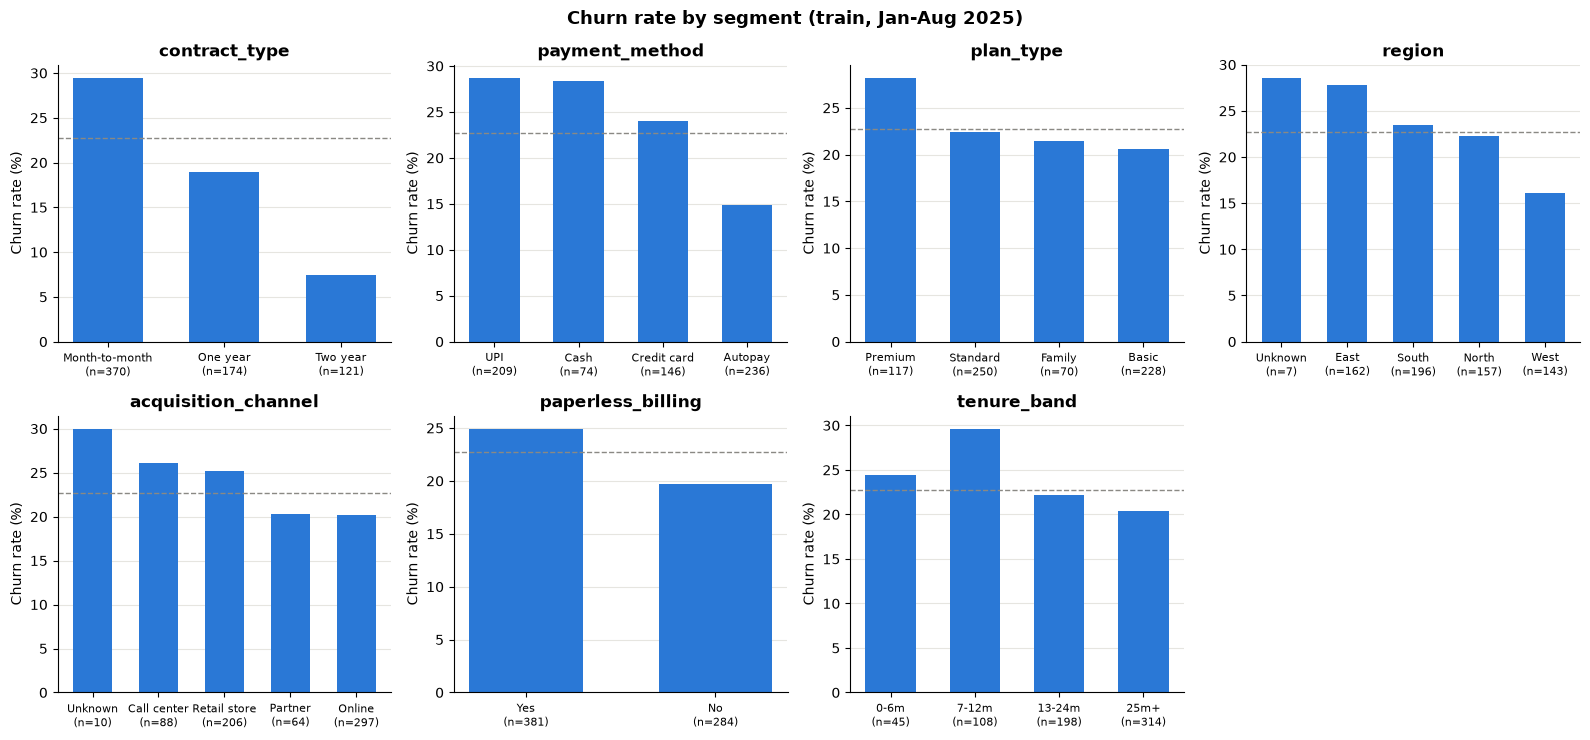

,feature,value,customers,churn_rate
0,contract_type,Month-to-month,370,0.295
1,contract_type,One year,174,0.190
2,contract_type,Two year,121,0.074
0,payment_method,UPI,209,0.287
1,payment_method,Cash,74,0.284
2,payment_method,Credit card,146,0.240
3,payment_method,Autopay,236,0.148
0,plan_type,Premium,117,0.282
1,plan_type,Standard,250,0.224
2,plan_type,Family,70,0.214


In [4]:
segment_cols = ["contract_type", "payment_method", "plan_type", "region",
                "acquisition_channel", "paperless_billing", "tenure_band"]
order = {"tenure_band": ["0-6m", "7-12m", "13-24m", "25m+"]}

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
segment_tables = []
for ax, col in zip(axes.flat, segment_cols):
    seg = train.groupby(col)[TARGET].agg(["mean", "size"])
    seg = seg.reindex(order[col]) if col in order else seg.sort_values("mean", ascending=False)
    labels = [f"{idx}\n(n={n})" for idx, n in zip(seg.index, seg["size"])]
    ax.bar(labels, seg["mean"] * 100, color=BLUE, width=0.6)
    ax.axhline(rate_train * 100, color=GREY, linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
    segment_tables.append(seg.assign(feature=col).rename_axis("value").reset_index())
axes.flat[-1].axis("off")
fig.suptitle("Churn rate by segment (train, Jan-Aug 2025)", fontweight="bold", fontsize=13)
save(fig, "churn_rate_by_segment")

seg_table = pd.concat(segment_tables)[["feature", "value", "size", "mean"]]
seg_table.rename(columns={"size": "customers", "mean": "churn_rate"}).round(3)

**What this shows:** contract type is the clearest segment. Month-to-month customers churn at about 30% against 7% for
two-year customers, who are locked in. Autopay customers churn at 15% against 24-29% for the other payment methods.
Region, plan, channel, paperless billing and tenure show smaller gaps, and some groups are tiny (for example
"Unknown" region, n=7), so their rates are noisy. This led to `is_month_to_month`, `is_autopay` and the combined
`stickiness` score; the categorical columns are kept for the model to weigh.

## 4. Numeric columns: churned vs stayed (train)

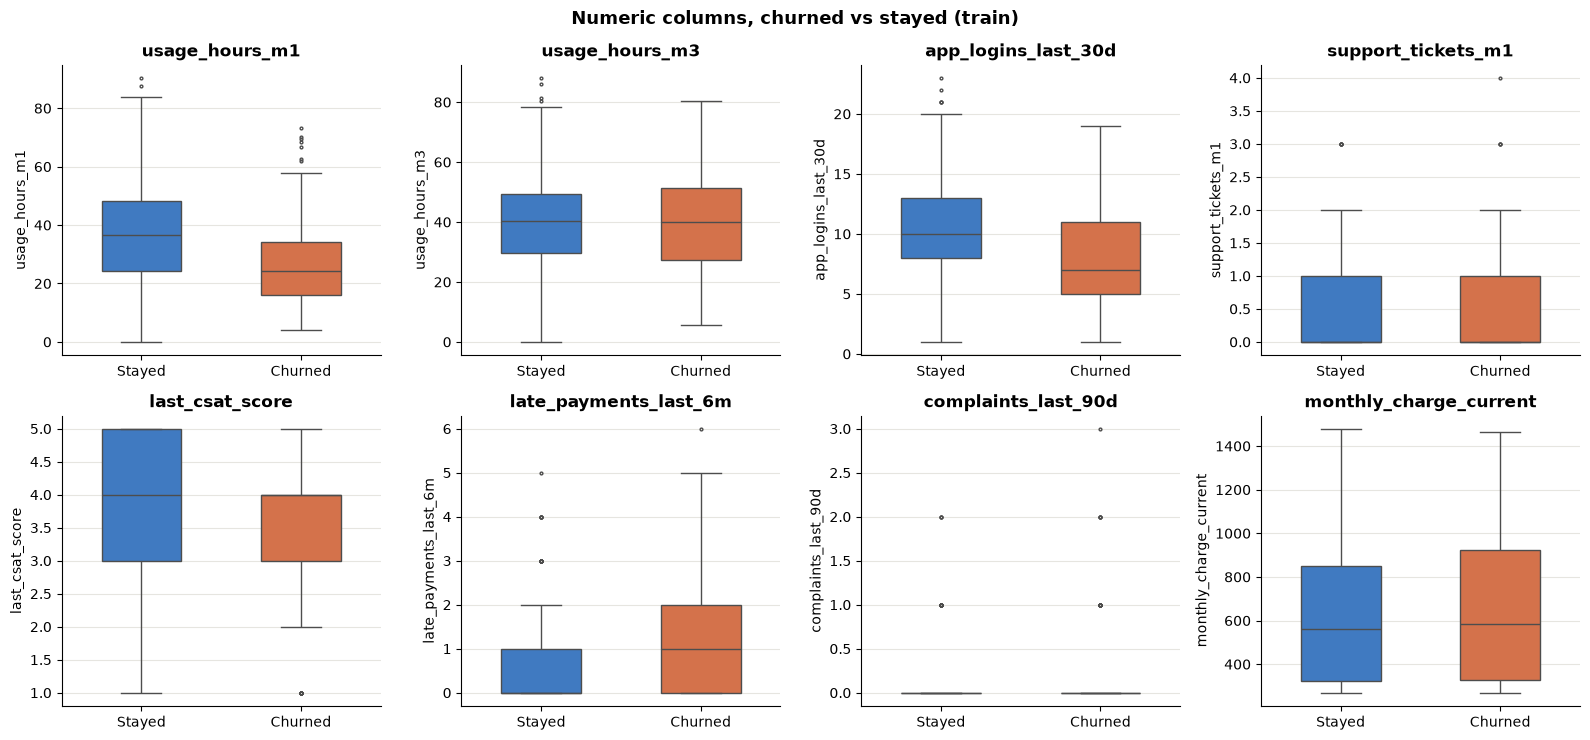

churn_label            Churned          Stayed        
                        median    mean  median    mean
usage_hours_m1           24.20   27.72   36.65   37.23
usage_hours_m3           39.90   39.50   40.45   39.78
app_logins_last_30d       7.00    8.12   10.00   10.54
support_tickets_m1        0.00    0.64    0.00    0.34
last_csat_score           4.00    3.45    4.00    3.76
late_payments_last_6m     1.00    1.32    0.00    0.72
complaints_last_90d       0.00    0.21    0.00    0.11
monthly_charge_current  584.13  647.77  560.10  613.26

In [5]:
numeric_cols = ["usage_hours_m1", "usage_hours_m3", "app_logins_last_30d", "support_tickets_m1",
                "last_csat_score", "late_payments_last_6m", "complaints_last_90d", "monthly_charge_current"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=train, x="churn_label", y=col, hue="churn_label", order=["Stayed", "Churned"],
                palette={"Stayed": BLUE, "Churned": ORANGE}, width=0.5, linewidth=1, fliersize=2,
                legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel(col)
fig.suptitle("Numeric columns, churned vs stayed (train)", fontweight="bold", fontsize=13)
save(fig, "numeric_boxplots")

train.groupby("churn_label")[numeric_cols].agg(["median", "mean"]).T.unstack().round(2)

**What this shows:** churners used the service *less* last month (median `usage_hours_m1` 24 vs 37 hours) and
logged in less, but their usage three months ago (`usage_hours_m3`) is almost the same as everyone else's
(about 40 hours). So **the drop in usage** matters more than the level. Most customers have 0 tickets and a CSAT of 4,
so the medians match. The means still show that churners have more tickets, more late payments and slightly lower
CSAT. The monthly charge alone barely differs.

## 5. Behaviour-change warning signs (train)

These signals are computed here only for EDA; notebook 03 builds them properly as features.

| Warning sign | Definition |
|---|---|
| Usage drop > 20% | (usage m1 - usage m3) / (usage m3 + 1) < -20% |
| Inactive > 30 days | days between last login and snapshot > 30 |
| Any open ticket | tickets in last 3 months - tickets resolved > 0 |
| 3+ billing issues | late payments + billing disputes (6 months) >= 3 |
| Unpaid amount > 0 | total billed - total paid (6 months) > 0 |
| Bill unpaid | no payment recorded for the last bill |

In [6]:
def add_signals(d):
    d = d.copy()
    d["usage_change_pct"] = (d["usage_hours_m1"] - d["usage_hours_m3"]) / (d["usage_hours_m3"] + 1) * 100
    d["days_since_login"] = (d["snapshot_date"] - d["last_login_date"]).dt.days
    d["open_tickets"] = d[["support_tickets_m1", "support_tickets_m2", "support_tickets_m3"]].sum(axis=1) \
        - d["tickets_resolved_last_90d"]
    d["billing_issues"] = d["late_payments_last_6m"] + d["billing_disputes_last_6m"]
    d["unpaid_amount"] = d["total_billed_last_6m"] - d["total_paid_last_6m"]
    return d

train = add_signals(train)
data = add_signals(data)

signals = {
    "Usage drop > 20%": train["usage_change_pct"] < -20,
    "Inactive > 30 days": train["days_since_login"] > 30,
    "Any open ticket": train["open_tickets"] > 0,
    "3+ billing issues": train["billing_issues"] >= 3,
    "Unpaid amount > 0": train["unpaid_amount"] > 0,
    "Bill unpaid": train["bill_unpaid_flag"] == 1,
}
rows = []
for name, flag in signals.items():
    rows.append({"warning_sign": name, "customers_with_sign": int(flag.sum()),
                 "churn_rate_present": train.loc[flag, TARGET].mean(),
                 "churn_rate_absent": train.loc[~flag, TARGET].mean()})
signal_table = pd.DataFrame(rows)
signal_table["ratio"] = signal_table["churn_rate_present"] / signal_table["churn_rate_absent"]
signal_table.round(3)

,warning_sign,customers_with_sign,churn_rate_present,churn_rate_absent,ratio
0,Usage drop > 20%,207,0.454,0.124,3.649
1,Inactive > 30 days,69,0.536,0.191,2.803
2,Any open ticket,210,0.352,0.169,2.082
3,3+ billing issues,64,0.516,0.196,2.626
4,Unpaid amount > 0,70,0.429,0.203,2.107
5,Bill unpaid,17,0.176,0.228,0.773


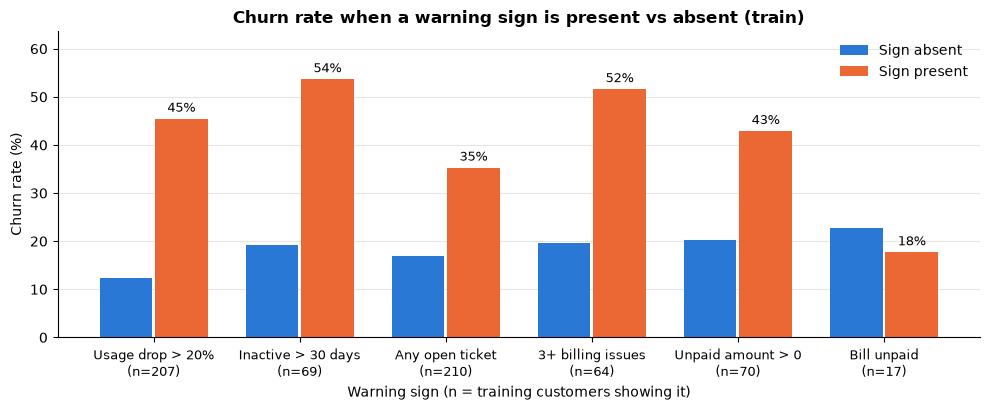

In [7]:
x = np.arange(len(signal_table))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(x - 0.19, signal_table["churn_rate_absent"] * 100, width=0.36, color=BLUE, label="Sign absent")
ax.bar(x + 0.19, signal_table["churn_rate_present"] * 100, width=0.36, color=ORANGE, label="Sign present")
for i, row in signal_table.iterrows():
    ax.annotate(f"{row['churn_rate_present']:.0%}", (i + 0.19, row["churn_rate_present"] * 100),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", fontsize=9)
ax.set_xticks(x, [f"{s}\n(n={n})" for s, n in zip(signal_table["warning_sign"], signal_table["customers_with_sign"])],
              fontsize=9)
ax.set_ylim(0, signal_table["churn_rate_present"].max() * 100 + 10)
ax.set_title("Churn rate when a warning sign is present vs absent (train)")
ax.set_xlabel("Warning sign (n = training customers showing it)")
ax.set_ylabel("Churn rate (%)")
ax.legend(frameon=False)
save(fig, "warning_signs")

**What this shows:** a usage drop of more than 20% is the strongest warning sign by ratio (45% vs 12% churn, about 3.6x)
and it affects many customers (207). Inactivity over 30 days and 3+ billing issues mark smaller groups with more
than 50% churn. Open tickets and unpaid amounts roughly double the churn rate. An unpaid *last* bill does **not**
raise churn in train (18% vs 23%), but only 17 customers have it, so that rate is too noisy to trust either way.
These results led to `usage_change_pct_m3_to_m1`, `usage_drop_flag`, `inactive_flag`, `days_since_login`,
`open_tickets` / `service_pain_score`, `billing_risk`, `unpaid_amount_6m` and `bill_unpaid_flag`.

## 6. Correlation heatmap (train)

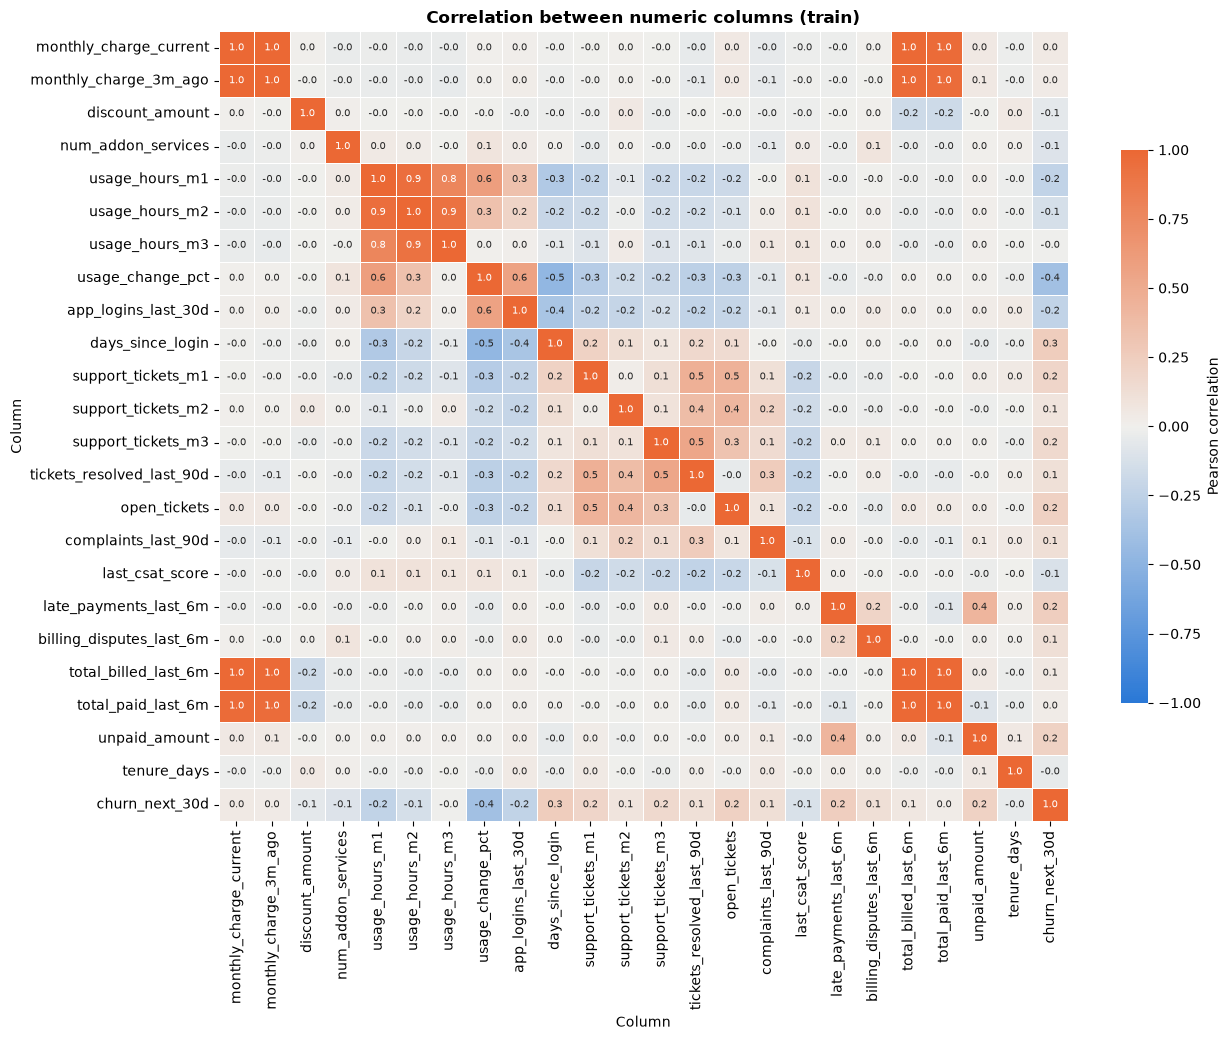

In [8]:
corr_cols = ["monthly_charge_current", "monthly_charge_3m_ago", "discount_amount", "num_addon_services",
             "usage_hours_m1", "usage_hours_m2", "usage_hours_m3", "usage_change_pct", "app_logins_last_30d",
             "days_since_login", "support_tickets_m1", "support_tickets_m2", "support_tickets_m3",
             "tickets_resolved_last_90d", "open_tickets", "complaints_last_90d", "last_csat_score",
             "late_payments_last_6m", "billing_disputes_last_6m", "total_billed_last_6m", "total_paid_last_6m",
             "unpaid_amount", "tenure_days", TARGET]
corr = train[corr_cols].corr()

# diverging map: blue (negative) - grey (zero) - orange (positive)
cmap = LinearSegmentedColormap.from_list("blue_grey_orange", [BLUE, "#f0efec", ORANGE])
fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(corr, cmap=cmap, vmin=-1, vmax=1, center=0, linewidths=0.5, linecolor="white",
            annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"label": "Pearson correlation", "shrink": 0.7},
            ax=ax)
ax.set_title("Correlation between numeric columns (train)")
ax.set_xlabel("Column")
ax.set_ylabel("Column")
save(fig, "correlation_heatmap")

In [9]:
top_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
top_corr.head(10).round(3).to_frame("correlation with churn (train)")

,correlation with churn (train)
usage_change_pct,-0.394
days_since_login,0.255
late_payments_last_6m,0.245
app_logins_last_30d,-0.240
usage_hours_m1,-0.239
open_tickets,0.222
unpaid_amount,0.214
support_tickets_m1,0.193
support_tickets_m3,0.158
usage_hours_m2,-0.137


**What this shows:** the strongest correlation with churn is usage change (-0.39: usage falling means churn rising),
followed by days since login, late payments, app logins and open tickets. Every correlation is moderate, so no single
column decides churn on its own. The heatmap also shows groups of columns that
are almost copies of each other (current charge, charge 3 months ago and total billed; the three usage months).
Keeping all of them would add no information, so notebook 03 removes one of each pair with |correlation| >= 0.9.

## 7. Single-feature ROC-AUC (train)

How well does one column on its own rank churners above non-churners?
0.5 means no better than a coin flip and 1.0 is a perfect ranking. A column that ranks *backwards* (low values =
churn) has an AUC below 0.5, so we report `max(AUC, 1 - AUC)` to measure strength regardless of direction.

,column,auc,strength,direction
0,usage_change_pct,0.251,0.749,lower = more churn
1,usage_hours_m1,0.326,0.674,lower = more churn
2,app_logins_last_30d,0.330,0.670,lower = more churn
3,days_since_login,0.653,0.653,higher = more churn
4,late_payments_last_6m,0.634,0.634,higher = more churn
5,open_tickets,0.622,0.622,higher = more churn
6,support_tickets_m1,0.610,0.610,higher = more churn
7,usage_hours_m2,0.403,0.597,lower = more churn
8,support_tickets_m3,0.586,0.586,higher = more churn
9,last_csat_score,0.423,0.577,lower = more churn


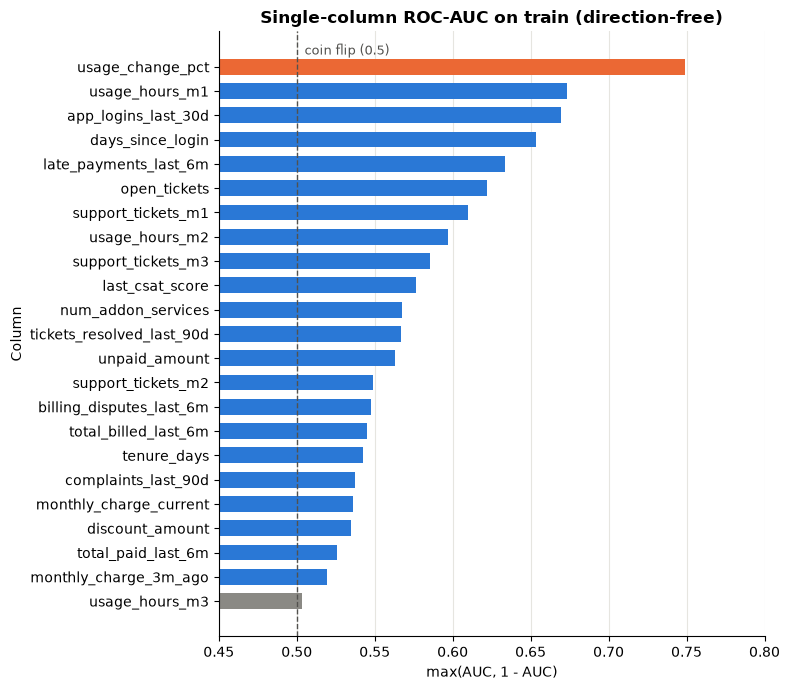

usage_hours_m3     strength = 0.503
usage_hours_m1     strength = 0.674
usage_change_pct   strength = 0.749


In [10]:
auc_cols = [c for c in corr_cols if c != TARGET]
auc_rows = []
for col in auc_cols:
    auc = roc_auc_score(train[TARGET], train[col])
    auc_rows.append({"column": col, "auc": auc, "strength": max(auc, 1 - auc),
                     "direction": "higher = more churn" if auc >= 0.5 else "lower = more churn"})
auc_table = pd.DataFrame(auc_rows).sort_values("strength", ascending=False).reset_index(drop=True)
display(auc_table.round(3))

fig, ax = plt.subplots(figsize=(8, 7))
colors = [ORANGE if c == "usage_change_pct" else (BLUE if c != "usage_hours_m3" else GREY) for c in auc_table["column"]]
ax.barh(auc_table["column"][::-1], auc_table["strength"][::-1], color=colors[::-1], height=0.65)
ax.axvline(0.5, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.505, len(auc_table) - 0.5, "coin flip (0.5)", fontsize=9, color="#52514e")
ax.set_xlim(0.45, 0.8)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Single-column ROC-AUC on train (direction-free)")
ax.set_xlabel("max(AUC, 1 - AUC)")
ax.set_ylabel("Column")
save(fig, "single_feature_auc")

for c in ["usage_hours_m3", "usage_hours_m1", "usage_change_pct"]:
    print(f"{c:18s} strength = {auc_table.set_index('column').loc[c, 'strength']:.3f}")

**What this shows:** usage three months ago (`usage_hours_m3`, grey) is close to a coin flip on its own,
but the **change** in usage (`usage_change_pct`, orange) is the strongest column of all. Each customer is compared
with their own earlier behaviour, and that comparison carries the signal. This is the main reason we build
change-based features instead of using raw levels.

## 8. Data-quality note: short-tenure customers with old usage (all customers)

`usage_hours_m3` is usage about three months before the snapshot. A customer who signed up less than 90 days
before the snapshot should have **no usage** that far back, but some do.

In [11]:
short = data[(data["tenure_days"] < 90) & (data["usage_hours_m3"] > 0)]
print("Customers with tenure < 90 days but usage 3 months ago > 0:", len(short))
print(short["split"].value_counts().reindex(["train", "validation", "test"]).to_dict())
short[["customer_id", "split", "signup_date", "snapshot_date", "tenure_days",
       "usage_hours_m1", "usage_hours_m2", "usage_hours_m3"]].sort_values("tenure_days").head(10)

Customers with tenure < 90 days but usage 3 months ago > 0: 21
{'train': 13, 'validation': 6, 'test': 2}


,customer_id,split,signup_date,snapshot_date,tenure_days,usage_hours_m1,usage_hours_m2,usage_hours_m3
215,CUST200393,train,2025-03-11,2025-03-31,20,29.3,30.1,31.7
620,CUST200421,train,2025-08-11,2025-08-31,20,43.7,43.6,41.7
870,CUST200320,test,2025-11-05,2025-11-30,25,62.3,59.4,57.6
773,CUST200404,validation,2025-10-01,2025-10-31,30,22.5,24.5,26.5
703,CUST200472,validation,2025-08-27,2025-09-30,34,36.8,41.5,48.7
4,CUST200033,train,2024-12-09,2025-01-31,53,62.5,56.8,53.0
72,CUST200918,train,2024-12-05,2025-01-31,57,52.5,48.2,48.5
296,CUST200249,train,2025-02-27,2025-04-30,62,36.9,36.3,37.0
960,CUST200334,test,2025-10-30,2025-12-31,62,42.0,37.3,35.4
251,CUST200784,train,2025-01-24,2025-03-31,66,29.2,26.9,25.9


**What this shows:** a few customers (about 2% of the data) have usage recorded before they signed up. This is
a quirk of the synthetic data generator, not something a real customer could do. We **document it and do not
change it**. There is no reliable way to know the "true" values, and the rows are kept as they are in the
modelling files. For these customers the usage-change feature is less trustworthy.

## 9. Key EDA insights, and the features they led to

| # | Insight (train data) | Feature(s) built in notebook 03 |
|---|---|---|
| 1 | Churn is 22% overall (151 of 665 in train), so accuracy is misleading; we use PR-AUC and recall | `class_weight="balanced"`, PR-AUC as main metric |
| 2 | Churn moves month to month (16-29%) and is lower in the test months, so we split by time | chronological train / validation / test |
| 3 | The **change** in usage is the strongest signal (AUC 0.75), while usage 3 months ago alone is a coin flip (0.50); a >20% drop gives 45% churn vs 12% | `usage_change_pct_m3_to_m1`, `usage_drop_flag`, `consecutive_usage_decline` |
| 4 | Month-to-month (30%) and non-autopay (24-29%) customers churn much more than two-year (7%) and autopay (15%) customers | `is_month_to_month`, `is_autopay`, `stickiness` |
| 5 | Customers inactive for over 30 days churn at 54% | `days_since_login`, `inactive_flag`, `engagement_score` |
| 6 | Open tickets (35% churn), complaints and low CSAT point to service pain | `open_tickets`, `resolution_rate`, `low_csat_flag`, `service_pain_score` |
| 7 | 3+ late payments/disputes (52% churn) and unpaid balances (43%) signal billing trouble; many raw billing/charge columns are near-copies (r >= 0.9) | `billing_risk`, `unpaid_amount_6m`, `payment_ratio_6m`; correlation filter in notebook 03 |

Data-quality caveat: 21 customers (13 train) have usage recorded before they signed up. This is a
generator quirk, documented and left unchanged.